### Task 1: Load Iris dataset, train Decision Tree and visualize it

Accuracy: 1.0


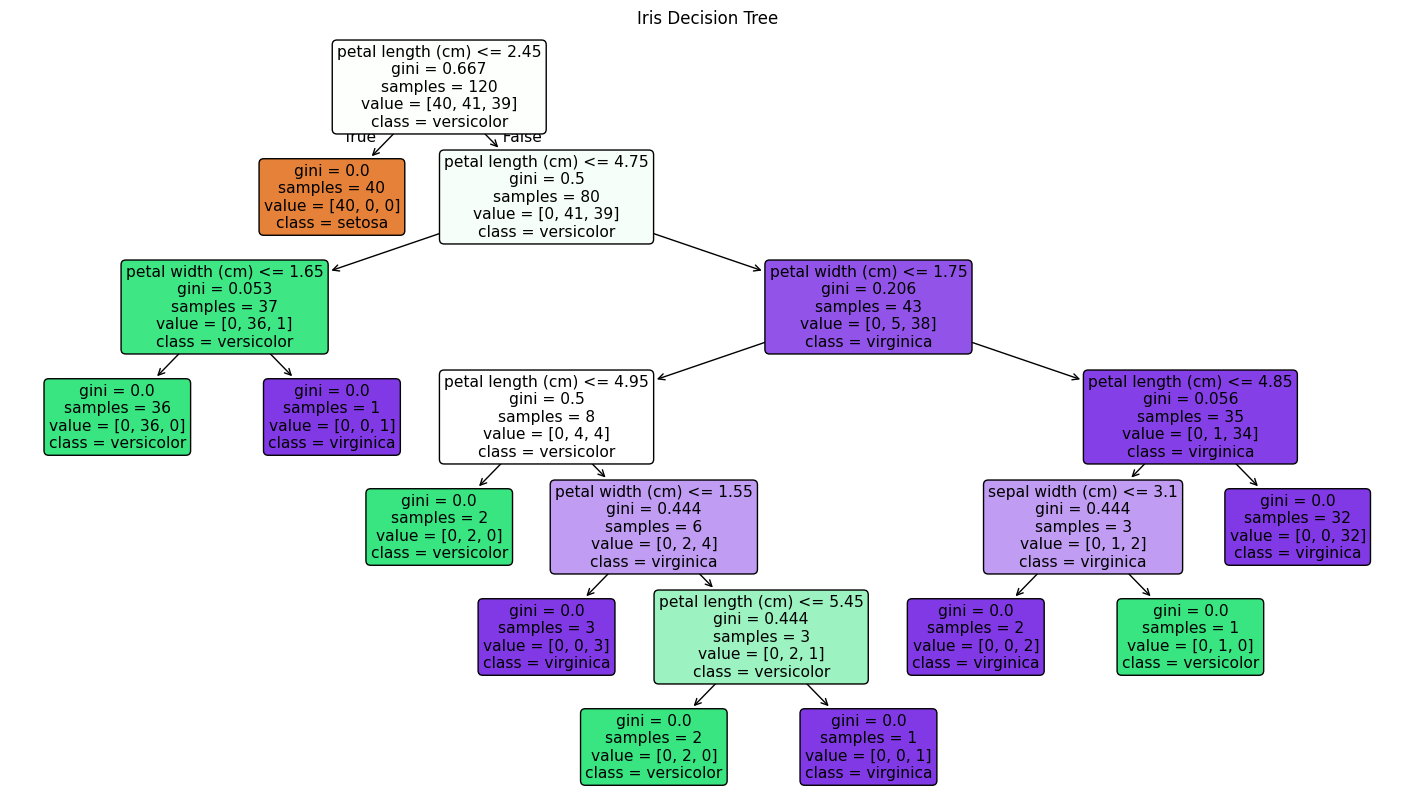

In [1]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Decision Tree
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Visualize Decision Tree
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Iris Decision Tree")
plt.show()

### Task 2: Compare Gini and Entropy

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Decision Tree using Gini
gini_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_model.fit(X_train, y_train)
gini_pred = gini_model.predict(X_test)

gini_accuracy = accuracy_score(y_test, gini_pred)

# Decision Tree using Entropy
entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model.fit(X_train, y_train)
entropy_pred = entropy_model.predict(X_test)

entropy_accuracy = accuracy_score(y_test, entropy_pred)

# Compare accuracy
print("Gini Accuracy:", gini_accuracy)
print("Entropy Accuracy:", entropy_accuracy)

Gini Accuracy: 1.0
Entropy Accuracy: 1.0


### Task 3: Limit maximum depth to 2

Full Tree Accuracy: 1.0
Depth 2 Tree Accuracy: 0.9666666666666667


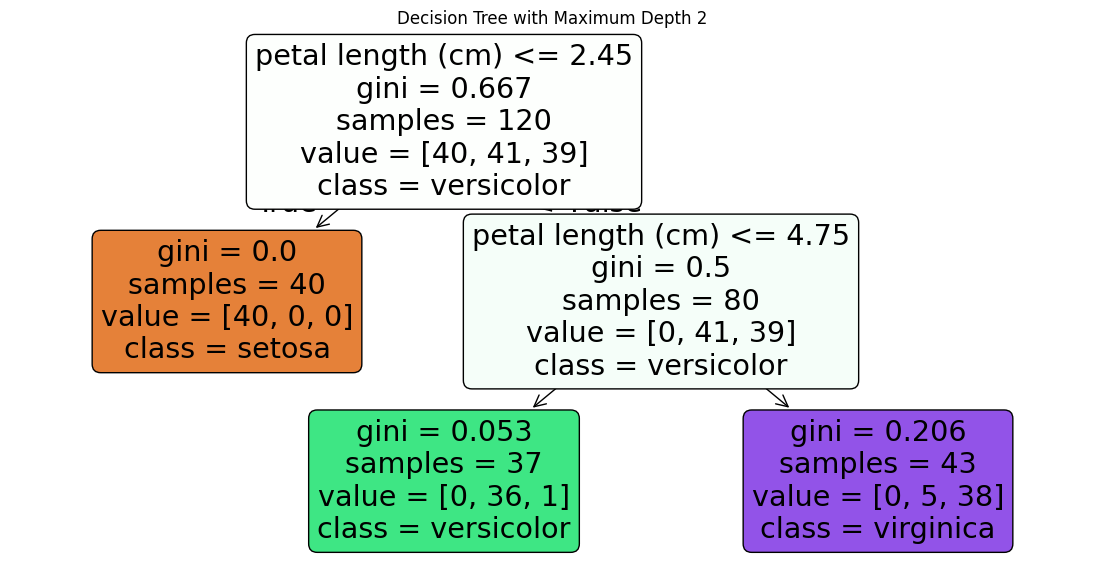

In [3]:
# Train Decision Tree with maximum depth 2
limited_model = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

limited_model.fit(X_train, y_train)

# Predict
limited_pred = limited_model.predict(X_test)

# Accuracy
print("Full Tree Accuracy:", accuracy_score(y_test, y_pred))
print("Depth 2 Tree Accuracy:", accuracy_score(y_test, limited_pred))

# Visualize limited tree
plt.figure(figsize=(14, 7))

plot_tree(
    limited_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree with Maximum Depth 2")
plt.show()

### Task 4: Feature Importance

In [4]:
import pandas as pd

# Get feature importance
importance = model.feature_importances_

# Create DataFrame
feature_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_df = feature_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_df)

             Feature  Importance
2  petal length (cm)    0.906143
3   petal width (cm)    0.077186
1   sepal width (cm)    0.016670
0  sepal length (cm)    0.000000


### Task 5: Food Delivery Dataset – Interpret the First Three Splits

Food Delivery Model Accuracy: 1.0


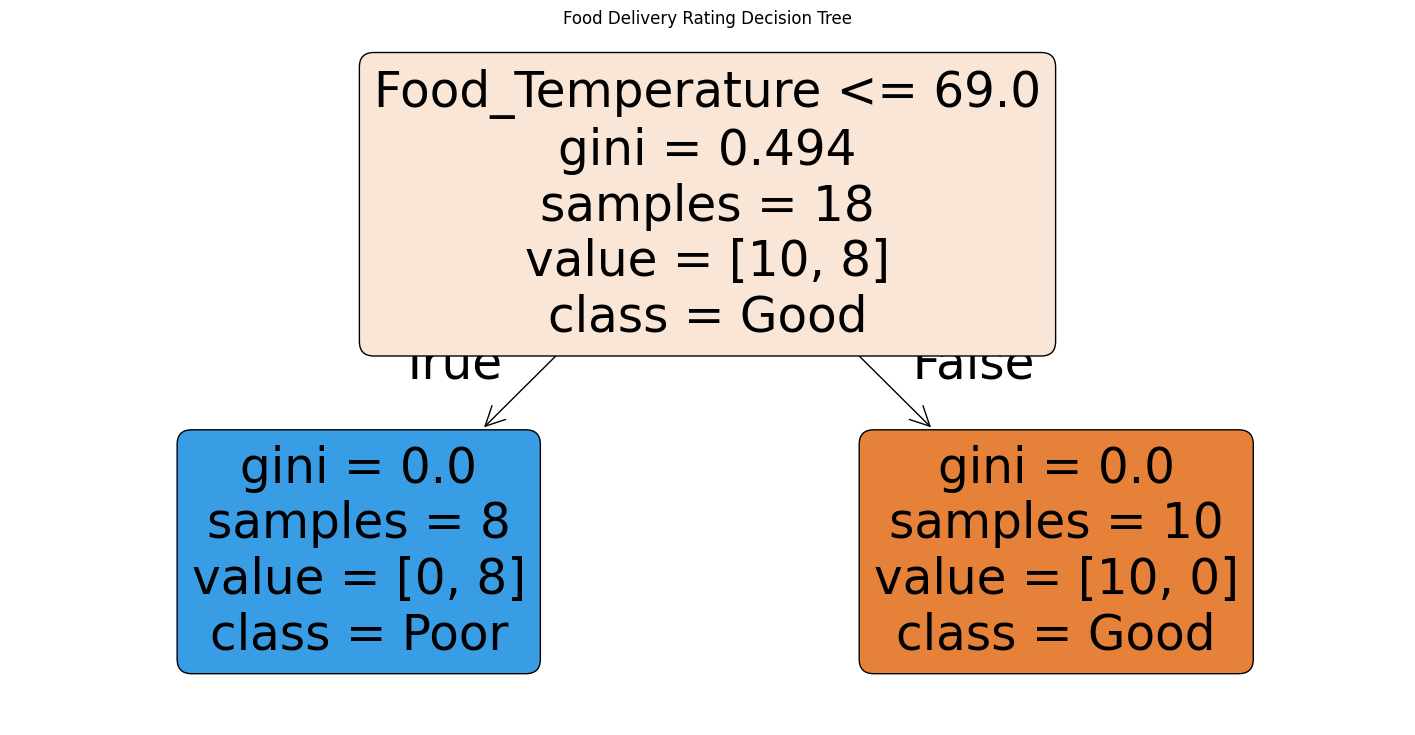

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create sample food delivery dataset
data = {
    "Delivery_Time": [15, 20, 25, 30, 35, 40, 45, 50,
                      18, 22, 28, 32, 38, 42, 48, 55,
                      12, 27, 33, 47, 52, 24, 36, 44],

    "Food_Temperature": [90, 85, 80, 75, 70, 60, 55, 45,
                         88, 82, 78, 72, 65, 58, 50, 40,
                         92, 79, 73, 52, 42, 84, 68, 56],

    "Order_Accuracy": [1, 1, 1, 1, 1, 0, 0, 0,
                       1, 1, 1, 1, 0, 0, 0, 0,
                       1, 1, 1, 0, 0, 1, 0, 0],

    "Rating": ["Good", "Good", "Good", "Good", "Good", "Poor",
               "Poor", "Poor", "Good", "Good", "Good", "Good",
               "Poor", "Poor", "Poor", "Poor", "Good", "Good",
               "Good", "Poor", "Poor", "Good", "Poor", "Poor"]
}

df = pd.DataFrame(data)

# Features and target
X = df[["Delivery_Time", "Food_Temperature", "Order_Accuracy"]]
y = df["Rating"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Train Decision Tree
food_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

food_model.fit(X_train, y_train)

# Predict and check accuracy
food_pred = food_model.predict(X_test)

print("Food Delivery Model Accuracy:",
      accuracy_score(y_test, food_pred))

# Visualize tree
plt.figure(figsize=(18, 9))

plot_tree(
    food_model,
    feature_names=X.columns,
    class_names=food_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Food Delivery Rating Decision Tree")
plt.show()